In [1]:
%load_ext autoreload
%autoreload 2

import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
import sys

# 1. Get the absolute path of the current script's directory
current_dir = os.getcwd()

# 2. Get the path of the parent directory
parent_dir = os.path.dirname(current_dir)

# 3. Add the parent directory to the top of sys.path
sys.path.insert(0, parent_dir)

import baselines,metrics


In [2]:
print(metrics.__file__)
print([name for name in dir(metrics) if not name.startswith("_")])


c:\Users\user\Desktop\Projects\Time-series ML\metrics.py
['QLIKE', 'RMSE', 'np', 'pd', 'plt']


In [3]:
print(baselines.__file__)
print([name for name in dir(baselines) if not name.startswith("_")])


c:\Users\user\Desktop\Projects\Time-series ML\baselines.py
['arch_model', 'ewm', 'garch', 'naive', 'np', 'pd', 'rolling']


In [4]:
data = yf.download("^GSPC", start="1990-01-01", auto_adjust=True)


log_returns = np.log(data["Close"]["^GSPC"]).diff().iloc[1:]


sq_returns = np.square(log_returns)
vol_of_5days = np.sqrt(sq_returns.rolling(5).mean()).shift(-5).iloc[:log_returns.shape[0] - 5]


train = vol_of_5days.loc["1990" : "2018"]
val = vol_of_5days.loc["2019" : "2022"]
test = vol_of_5days.loc["2023" : ]


print(train.head())
print(train.tail())
print(val.head())
print(val.tail())
print(test.head())
print(test.tail())


[*********************100%***********************]  1 of 1 completed

Date
1990-01-03    0.008669
1990-01-04    0.007915
1990-01-05    0.012972
1990-01-08    0.013387
1990-01-09    0.013250
Name: ^GSPC, dtype: float64
Date
2018-12-24    0.022317
2018-12-26    0.012456
2018-12-27    0.019198
2018-12-28    0.019442
2018-12-31    0.019553
Name: ^GSPC, dtype: float64
Date
2019-01-02    0.019630
2019-01-03    0.016240
2019-01-04    0.005983
2019-01-07    0.005621
2019-01-08    0.005976
Name: ^GSPC, dtype: float64
Date
2022-12-23    0.009848
2022-12-27    0.010246
2022-12-28    0.010157
2022-12-29    0.012052
2022-12-30    0.012003
Name: ^GSPC, dtype: float64
Date
2023-01-03    0.012269
2023-01-04    0.013109
2023-01-05    0.012113
2023-01-06    0.006921
2023-01-09    0.006972
Name: ^GSPC, dtype: float64
Date
2026-10-08    0.005836
2026-10-09    0.007153
2026-10-12    0.007378
2026-10-13    0.007485
2026-10-14    0.006294
Name: ^GSPC, dtype: float64


In [5]:
print(data.columns)


MultiIndex([( 'Close', '^GSPC'),
            (  'High', '^GSPC'),
            (   'Low', '^GSPC'),
            (  'Open', '^GSPC'),
            ('Volume', '^GSPC')],
           names=['Price', 'Ticker'])


0.6362943611198906


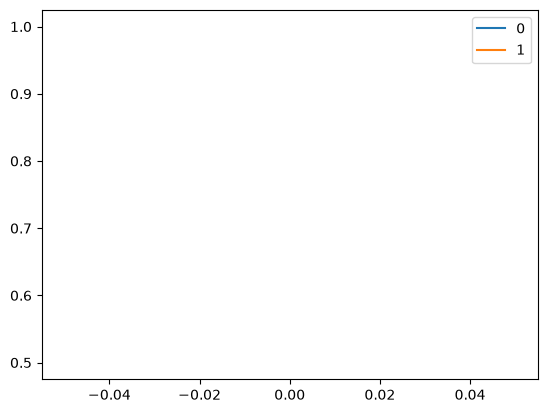

In [6]:
pred = pd.Series([1])
act = pd.Series([0.5])

print(metrics.QLIKE(pred,act))

In [7]:
print(val.head())

Date
2019-01-02    0.019630
2019-01-03    0.016240
2019-01-04    0.005983
2019-01-07    0.005621
2019-01-08    0.005976
Name: ^GSPC, dtype: float64


In [8]:
import inspect
print(baselines.__file__)
print(inspect.getsource(baselines.garch))

c:\Users\user\Desktop\Projects\Time-series ML\baselines.py
def garch(returns: pd.Series, cutoff: str) -> pd.Series:
    """GARCH(1,1) forecast of next-week volatility (typical daily move).

    Like EWMA, but reaction (alpha), memory (beta) and a long-run anchor (omega)
    are learned from data before `cutoff`, instead of being fixed.
    """
    r100 = returns * 100  # arch fits more reliably on values around 1
    model = arch_model(r100, mean="Zero", vol="GARCH", p=1, q=1)
    res = model.fit(last_obs=cutoff, disp="off")              # learn omega, alpha, beta before cutoff
    fc = res.forecast(horizon=5, start=cutoff, reindex=False)  # 5 daily variances per date
    daily_var = fc.variance / 100**2                          # undo the scaling
    return np.sqrt(daily_var.mean(axis=1))  



In [9]:
print(type(log_returns))
garch = baselines.garch(log_returns,"2019-01-02")

<class 'pandas.Series'>


0.4935176358500769
1.0081561305501578
0.6309387687914793
0.5560741281683151


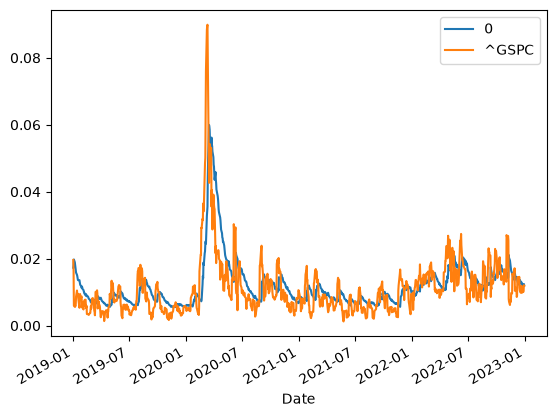

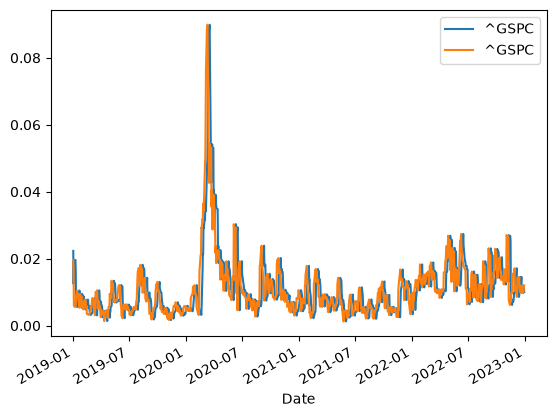

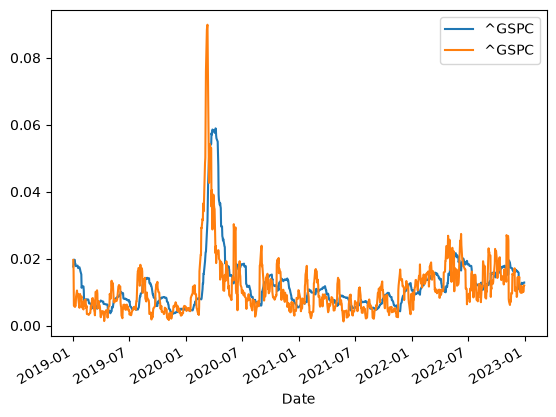

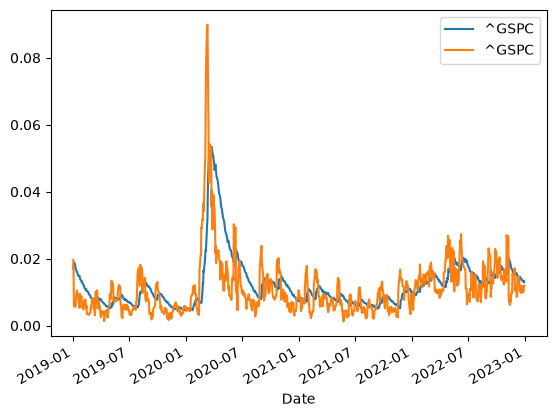

In [13]:
naive = baselines.naive(log_returns)
rolling = baselines.rolling(log_returns)
ewm = baselines.ewm(log_returns)

print(metrics.QLIKE(garch,val))
print(metrics.QLIKE(naive,val))
print(metrics.QLIKE(rolling,val))
print(metrics.QLIKE(ewm,val))